<a href="https://colab.research.google.com/github/ikwak2/bio_sig_class/blob/main/04_ecg_stmem_teaching_qv_light.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습 04. ECG 사전학습 모델: Linear head부터 LoRA까지

이 실습은 **30초 ECG에 `V` 박동 주석이 하나 이상 있는지** 예측합니다. 전문가의 `V` 주석은 정답을 만드는 데만 사용하며 모델 입력에는 넣지 않습니다.

학습 순서는 다음과 같습니다.

1. ECG 한 구간을 네 개의 9초 crop으로 바꾸는 과정을 이해합니다.
2. **사전학습 encoder를 고정하고 linear head만 학습**합니다.
3. **LoRA를 추가해 encoder 표현 일부도 조정**합니다.
4. 두 방법의 설정을 검증 자료로 결정한 뒤, 마지막에 test를 비교합니다.

**실행 방법:** Colab에서 `런타임 → 런타임 유형 변경 → GPU`를 선택하세요. 이전 버전을 실행했다면 런타임을 다시 시작하고 위에서부터 순서대로 실행합니다. 다운로드와 특징 추출에는 시간이 걸리며 진행 표시를 확인하면 됩니다.

이번 LoRA 기본값은 Q·V 각각 rank 2, 마지막 4개 블록이며, 실험 B의 설정 셀에서 쉽게 바꿀 수 있습니다. 결과는 직접 실행할 때 생성됩니다.

## 1. 환경 준비

필요한 패키지를 설치합니다.

In [ ]:
%pip install -q wfdb

In [ ]:
# 이 셀에서는 계산에 필요한 도구를 불러오고 실험 조건을 한곳에 모읍니다.
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import sys
import subprocess
import hashlib
import json
import time
import random
import urllib.request
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import wfdb
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (
    average_precision_score, roc_auc_score, balanced_accuracy_score,
    f1_score, recall_score, confusion_matrix, ConfusionMatrixDisplay,
)
from IPython.display import display

# 경로: data는 원본 자료, results는 이번 실행 결과를 저장하는 폴더입니다.
ROOT = Path.cwd()
DATA = ROOT / 'data' / 'mitdb'
OUT = ROOT / 'results' / 'ecg_stmem_qv_light'
REPO = ROOT / 'stmem_build' / 'ST-MEM'
CKPT = ROOT / 'stmem_build' / 'st_mem_vit_base_encoder.pth'
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# 같은 사전학습 모델을 사용하도록 코드 버전과 가중치의 지문을 고정합니다.
COMMIT = '311c6446894dee4126db8d2520024e9f62cf1616'
WEIGHT_ID = '1E7J-A1HqWa2f08T6Sfk5uWk-_CFJhOYQ'
EXPECTED_SHA256 = '6f63d370fd1a2ccf2fbddd681571adf985eeae3f652973f0071342a39b7793d6'

# 같은 기록의 겹치는 창이 train과 test에 동시에 들어가지 않게 기록별로 나눕니다.
SPLITS = {
    'train': ['100', '101', '103', '106', '108', '119'],
    'val': ['105', '112', '200'],
    'test': ['117', '203', '208'],
}

FS = 250                         # 모델에 넣을 신호의 초당 샘플 수
WINDOW_S = 30                    # 정답 하나를 붙일 원래 구간 길이
HOP_S = 15                       # 다음 30초 창으로 이동하는 간격
CROP_S = 9                       # ST-MEM에 한 번 넣을 신호 길이
STARTS_S = [0, 7, 14, 21]        # 30초 창 안에서 각 crop을 시작할 시각
LEAD_INDEX = 1                   # 표준 lead 순서에서 II의 인덱스: I=0, II=1

SEED = 11
EPOCHS = 3
BAG_BATCH = 4                    # 한 미니배치의 30초 구간 개수
ACCUM_STEPS = 4                  # 보통 4 × 4 = 16개 구간의 gradient를 모아 갱신
HEAD_LR = 1e-3                  # Linear head의 학습률. LoRA 설정은 실험 B의 별도 셀에 있습니다.

# 실습은 Colab GPU를 기준으로 진행합니다.
if not torch.cuda.is_available():
    raise RuntimeError('Colab 메뉴에서 GPU 런타임을 선택한 뒤 다시 실행하세요.')
DEVICE = torch.device('cuda')
# 지원 GPU에서는 BF16, 그 외에는 FP16 autocast를 사용합니다.
AMP_ENABLED = True
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

torch.set_num_threads(min(4, torch.get_num_threads()))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print('실행 장치:', DEVICE)
print('PyTorch:', torch.__version__, '/ GPU:', torch.cuda.get_device_name(0))
print('Autocast dtype:', AMP_DTYPE)

def amp_context():
    # autocast는 연산 정밀도를 조절합니다. 4-bit 양자화와는 다릅니다.
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_ENABLED)


실행 장치: cuda
PyTorch: 2.14.1+cu130 / GPU: Tesla T4
Autocast dtype: torch.bfloat16


## 2. 입력과 정답 이해하기

**한 행은 박동 하나가 아니라 30초 ECG 구간 하나입니다.**

- `target=1`: 30초 안에 전문가가 `V`로 주석한 박동이 하나 이상 있습니다.
- `target=0`: `V` 주석이 없습니다. 다른 부정맥이 포함될 수 있으므로 “완전 정상”이라는 뜻은 아닙니다.
- 원본 360 Hz에서 30초는 `360 × 30 = 10,800`개 값입니다.
- 250 Hz로 바꾸면 30초는 7,500개 값, 9초 crop 하나는 2,250개 값입니다.

| 기호 | 의미 | 이 실습의 크기 |
|---|---|---:|
| B | 한 배치의 30초 구간 수 | 보통 4 |
| K | 한 구간에서 꺼낸 crop 수 | 4 |
| C | 신호 채널 수 | 1 |
| L | crop 하나의 샘플 수 | 2,250 |
| D | crop 하나의 encoder 특징 수 | 768 |

입력 모양은 **`(B, K, C, L) = (B, 4, 1, 2250)`**입니다. 네 crop은 함께 하나의 30초 정답을 예측합니다. 각 crop에 별도의 양성 정답을 붙이지 않습니다.

## 3. 공식 ST-MEM 코드와 가중치 준비

이 셀은 약 341 MB의 공개 encoder를 내려받습니다. SHA256은 파일이 정상적으로 내려왔는지 확인하는 지문입니다. 논문의 사전학습을 여기서 새로 수행하지는 않습니다.

출처: [ST-MEM 논문, ICLR 2024](https://openreview.net/forum?id=WcOohbsF4H), [공식 구현](https://github.com/vuno/ST-MEM). 공식 코드의 라이선스는 CC BY-NC 4.0입니다.

In [ ]:
# 공식 저장소가 없을 때만 clone하고, 지정한 commit으로 맞춥니다.
if not REPO.exists():
    REPO.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(['git', 'clone', 'https://github.com/vuno/ST-MEM.git', str(REPO)], check=True)
subprocess.run(['git', '-C', str(REPO), 'checkout', COMMIT], check=True, capture_output=True)
assert subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip() == COMMIT
sys.path.insert(0, str(REPO))
from models.encoder.st_mem_vit import st_mem_vit_base


def file_sha256(path):
    # 큰 파일을 한꺼번에 메모리에 올리지 않고 1 MB씩 읽습니다.
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def ensure_checkpoint():
    import gdown
    CKPT.parent.mkdir(parents=True, exist_ok=True)
    if CKPT.exists() and file_sha256(CKPT) == EXPECTED_SHA256:
        print('정상 checkpoint를 재사용합니다:', CKPT.name)
        return EXPECTED_SHA256

    # 임시 파일로 먼저 받은 뒤 지문이 맞을 때만 정식 이름으로 바꿉니다.
    temporary = CKPT.with_suffix('.download')
    for attempt in range(1, 4):
        try:
            temporary.unlink(missing_ok=True)
            print(f'공식 encoder 다운로드: {attempt}/3')
            gdown.download(id=WEIGHT_ID, output=str(temporary), quiet=False)
            if not temporary.exists() or file_sha256(temporary) != EXPECTED_SHA256:
                raise RuntimeError('받은 파일의 SHA256이 예상값과 다릅니다.')
            temporary.replace(CKPT)
            return EXPECTED_SHA256
        except Exception as error:
            temporary.unlink(missing_ok=True)
            if attempt == 3:
                raise RuntimeError('공식 README의 encoder 파일을 다음 경로에 넣고 재실행하세요: ' + str(CKPT)) from error
            time.sleep(2)

weight_sha = ensure_checkpoint()
print('Checkpoint SHA256:', weight_sha)

공식 encoder 다운로드: 1/3


Downloading...
From (original): https://drive.google.com/uc?id=1E7J-A1HqWa2f08T6Sfk5uWk-_CFJhOYQ
From (redirected): https://drive.google.com/uc?id=1E7J-A1HqWa2f08T6Sfk5uWk-_CFJhOYQ&confirm=t&uuid=a01593a9-8da4-4edb-b62f-e86e8a54e1c3
To: /content/stmem_build/st_mem_vit_base_encoder.download
100%|██████████| 341M/341M [00:03<00:00, 88.4MB/s]


Checkpoint SHA256: 6f63d370fd1a2ccf2fbddd681571adf985eeae3f652973f0071342a39b7793d6


## 4. 30초 창에서 네 개의 9초 crop 만들기

crop 범위는 `[0,9)`, `[7,16)`, `[14,23)`, `[21,30)`초입니다. 이웃 crop이 2초씩 겹쳐 30초 전체를 덮습니다.

전처리 순서는 **360→250 Hz resampling → crop 추출 → high-pass 0.67 Hz → low-pass 40 Hz → crop별 z-score**입니다. High-pass는 느린 기저선 변동을, low-pass는 40 Hz보다 높은 성분을 줄입니다. 필터는 5차 Butterworth 양방향 필터입니다. 미래 샘플도 이용하므로 오프라인 실습에 해당합니다.

z-score는 crop마다 평균을 빼고 표준편차로 나눕니다. 단위 크기를 맞추지만 원래의 절대 진폭 정보는 줄어듭니다. 전문가 주석은 필터링이나 crop 특징 계산에 사용하지 않습니다.

In [ ]:
def download_record(record):
    # .hea: 채널/샘플링 정보, .dat: 실제 신호, .atr: 전문가 박동 주석
    for extension in ['hea', 'dat', 'atr']:
        path = DATA / f'{record}.{extension}'
        if path.exists() and path.stat().st_size > 0:
            continue
        temporary = path.with_suffix(path.suffix + '.part')
        try:
            url = f'https://physionet.org/files/mitdb/1.0.0/{path.name}'
            with urllib.request.urlopen(url, timeout=90) as response:
                temporary.write_bytes(response.read())
            temporary.replace(path)
        finally:
            temporary.unlink(missing_ok=True)


# sos 형식은 고차 필터를 안정적으로 계산하기 위한 표현입니다.
highpass_sos = signal.butter(5, 0.67, btype='highpass', fs=FS, output='sos')
lowpass_sos = signal.butter(5, 40, btype='lowpass', fs=FS, output='sos')


# 반환값 안내:
# bags는 (구간 수, crop 4개, 채널 1개, 샘플 2250개)이고,
# meta에는 각 구간의 기록 번호/분할/시각/정답이 들어갑니다.
# example_signal과 example_v_times는 설명 그림을 그리기 위한 예시입니다.
def prepare_bags():
    all_records = sum(SPLITS.values(), [])
    assert len(all_records) == len(set(all_records)), '같은 기록이 여러 split에 있습니다.'
    with ThreadPoolExecutor(max_workers=4) as pool:
        list(tqdm(pool.map(download_record, all_records), total=len(all_records), desc='Download records'))

    bag_list, rows = [], []
    example_signal, example_v_times = None, None
    for split, records in SPLITS.items():
        for record in records:
            ecg = wfdb.rdrecord(str(DATA / record))
            annotation = wfdb.rdann(str(DATA / record), 'atr')
            if 'MLII' not in ecg.sig_name:
                raise ValueError(f'{record}: MLII 채널을 찾지 못했습니다.')
            channel = ecg.sig_name.index('MLII')
            assert ecg.fs == 360 and ecg.units[channel] == 'mV'

            # 250/360 = 25/36. anti-aliasing 처리를 포함해 샘플 수를 바꿉니다.
            resampled = signal.resample_poly(ecg.p_signal[:, channel], 25, 36).astype('float32')
            # 주석의 sample 번호는 원본 360 Hz 기준입니다. 초 단위로 바꿔 라벨에만 사용합니다.
            v_times = np.asarray(annotation.sample)[np.asarray(annotation.symbol) == 'V'] / 360

            for start_sample in range(0, len(resampled) - WINDOW_S * FS + 1, HOP_S * FS):
                window = resampled[start_sample:start_sample + WINDOW_S * FS]  # (7500,)
                crops = np.stack([
                    window[start * FS:(start + CROP_S) * FS] for start in STARTS_S
                ])  # (4, 2250)
                crops = signal.sosfiltfilt(highpass_sos, crops, axis=-1)
                crops = signal.sosfiltfilt(lowpass_sos, crops, axis=-1)
                # axis=-1은 시간 샘플 축입니다. 네 crop 각각을 따로 정규화합니다.
                crops = (crops - crops.mean(-1, keepdims=True)) / np.maximum(
                    crops.std(-1, keepdims=True), 1e-6
                )
                start_s = start_sample / FS
                # 창은 [시작, 끝)입니다. 끝에 놓인 주석은 다음 창에서 포함할 수 있습니다.
                target = int(np.any((v_times >= start_s) & (v_times < start_s + WINDOW_S)))
                rows.append({'record': record, 'split': split, 'start_s': start_s,
                             'end_s': start_s + WINDOW_S, 'target': target})
                # 채널 축 1개를 추가합니다: (4,2250) → (4,1,2250).
                bag_list.append(crops[:, None, :].astype('float32'))
                if example_signal is None and target == 1:
                    example_signal = window.copy()
                    example_v_times = v_times[(v_times >= start_s) & (v_times < start_s + WINDOW_S)] - start_s
            print('준비 완료:', record, split)
    return np.stack(bag_list), pd.DataFrame(rows), example_signal, example_v_times

bags, meta, raw_example, example_v = prepare_bags()
assert bags.shape == (1428, 4, 1, 2250)
assert np.isfinite(bags).all()
assert meta.groupby('record')['split'].nunique().eq(1).all()
split_masks = {split: meta['split'].eq(split).to_numpy() for split in SPLITS}
y = meta['target'].to_numpy(dtype='float32')
meta.to_csv(OUT / 'manifest.csv', index=False)
print('전체 입력 shape:', bags.shape)
display(meta.groupby('split', sort=False).agg(windows=('target', 'size'), V_windows=('target', 'sum')))

Download records:   0%|          | 0/12 [00:00<?, ?it/s]

준비 완료: 100 train
준비 완료: 101 train
준비 완료: 103 train
준비 완료: 106 train
준비 완료: 108 train
준비 완료: 119 train
준비 완료: 105 val
준비 완료: 112 val
준비 완료: 200 val
준비 완료: 117 test
준비 완료: 203 test
준비 완료: 208 test
전체 입력 shape: (1428, 4, 1, 2250)


,windows,V_windows
split,,
train,714,227
val,357,179
test,357,237


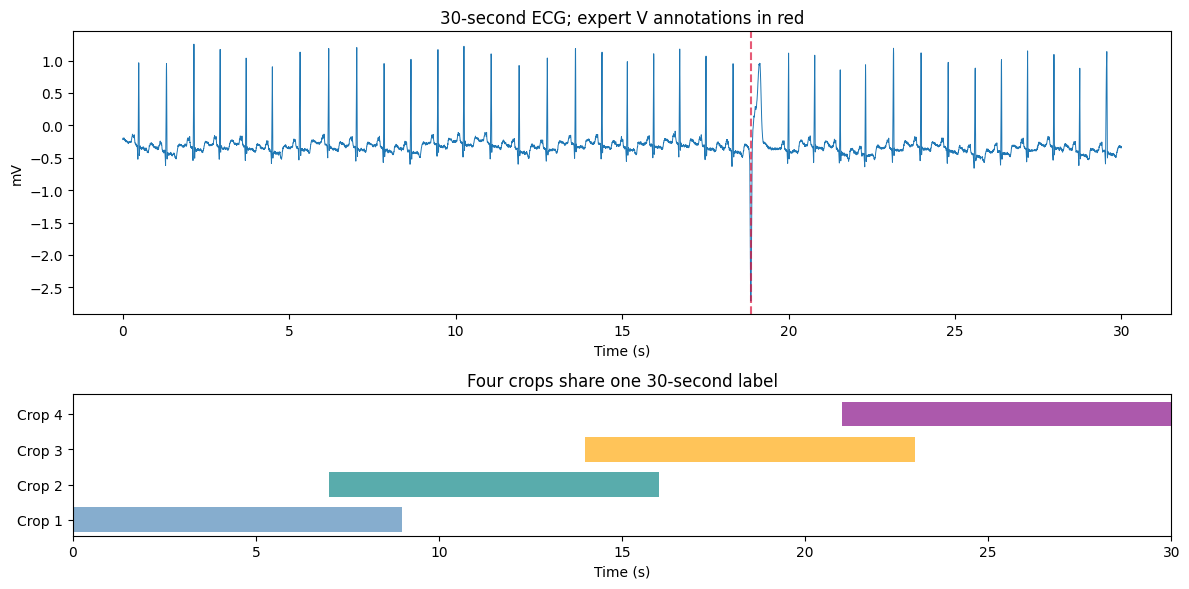

In [ ]:
# 위쪽: 30초 원본 신호와 V 주석. 아래쪽: 네 crop이 덮는 범위.
fig, axes = plt.subplots(2, 1, figsize=(12, 6), gridspec_kw={'height_ratios': [2, 1]})
times = np.arange(len(raw_example)) / FS
axes[0].plot(times, raw_example, lw=0.7)
for v_time in example_v:
    axes[0].axvline(v_time, color='crimson', ls='--', alpha=0.7)
axes[0].set(xlabel='Time (s)', ylabel='mV', title='30-second ECG; expert V annotations in red')
for number, (start, color) in enumerate(zip(STARTS_S, ['steelblue', 'teal', 'orange', 'purple'])):
    axes[1].broken_barh([(start, CROP_S)], (number + 0.1, 0.7), facecolors=color, alpha=0.65)
axes[1].set(xlim=(0, 30), ylim=(0, 4), yticks=np.arange(4) + 0.45,
            yticklabels=[f'Crop {number + 1}' for number in range(4)],
            xlabel='Time (s)', title='Four crops share one 30-second label')
plt.tight_layout()
plt.show()

**확인 질문:** 첫 번째 crop에 V가 없고 두 번째 crop에만 V가 있다면 이 30초 창의 정답은 무엇일까요? 정답은 `1`입니다. 네 crop을 함께 처리하는 이유입니다.

## 5. 사전학습 encoder와 특징 벡터

**Encoder**는 파형을 숫자 특징 벡터로 바꿉니다. ST-MEM은 crop 하나를 75개 샘플씩(250 Hz에서 0.3초) 30개 패치로 나누고, 최종적으로 768차원 벡터를 반환합니다. 여기서는 사전학습 때의 decoder를 사용하지 않습니다.

공개 가중치는 12유도용입니다. 새 모델은 1채널로 만들고 **II의 lead embedding을 선택**합니다. MIT-BIH의 MLII는 modified Lead II이므로 표준 II와 동일하지 않습니다. 이번 선택은 명시적인 근사입니다.

In [ ]:
# 공개 가중치를 읽는 함수입니다. 호출할 때마다 새 encoder를 만듭니다.
# 따라서 LoRA로 학습한 encoder가 linear 기준선에 섞여 들어가지 않습니다.
def make_encoder():
    # 매번 같은 구조와 같은 초기화 순서에서 시작합니다.
    # 이후 모든 실제 encoder 가중치는 공개 checkpoint 값으로 덮어씁니다.
    torch.manual_seed(SEED)
    encoder = st_mem_vit_base(num_leads=1, num_classes=None, seq_len=2250, patch_size=75)
    checkpoint = torch.load(CKPT, map_location='cpu', weights_only=True)
    source_state = checkpoint['model']
    lead_keys = [key for key in source_state if key.startswith('lead_embeddings.')]
    assert len(lead_keys) == 12
    state = {key: value for key, value in source_state.items()
             if not key.startswith('lead_embeddings.') and not key.startswith('head.')}
    # 12개 lead 중 II 하나를 새 모델의 첫 번째(유일한) lead로 연결합니다.
    state['lead_embeddings.0'] = source_state[f'lead_embeddings.{LEAD_INDEX}'].clone()
    assert set(state) == set(encoder.state_dict())
    encoder.load_state_dict(state, strict=True)  # 빠진 키/다른 크기를 허용하지 않습니다.
    for parameter in encoder.parameters():
        parameter.requires_grad = False        # encoder의 원래 가중치를 학습하지 않습니다.
    encoder.eval().to(DEVICE)
    print('공개 encoder를 읽었습니다. 모든 기본 가중치는 고정합니다.')
    return encoder

### 코드에서 자주 나오는 표현

| 표현 | 읽는 방법 |
|---|---|
| `torch.from_numpy(x)` | NumPy 배열을 PyTorch tensor로 바꿉니다. |
| `.to(DEVICE)` | 계산할 장치인 GPU로 옮깁니다. |
| `nn.Module` | PyTorch 모델을 만드는 기본 틀입니다. |
| `__init__` / `forward` | 모델의 부품 정의 / 실제 계산 순서입니다. |
| `requires_grad=False` | 해당 파라미터의 gradient를 계산하지 않습니다. |
| `state_dict()` | 파라미터 이름과 tensor를 짝지은 사전으로 저장·복원에 사용합니다. |
| `.detach().cpu().clone()` | 계산 그래프에서 분리하고 CPU에 독립 복사본을 보관합니다. 선택한 epoch를 저장할 때 사용합니다. |
| `net.train()` / `net.eval()` | 학습용 / 예측용 동작 모드입니다. 가중치를 고정하는 명령은 아닙니다. |


## 6. 실험 A: Encoder 고정 + Linear head만 학습

네 crop을 encoder에 넣으면 `(B,4,768)` 특징을 얻습니다.

1. crop 축의 **평균**으로 768개 숫자를 만듭니다.
2. 같은 축의 **좌표별 최댓값**으로 768개 숫자를 만듭니다.
3. 두 벡터를 연결해 **1,536차원** 특징을 만듭니다.
4. `Linear(1536,1)`이 logit 하나를 계산합니다. `sigmoid(logit)`이 V 포함 점수입니다.

$$g=[\mathrm{mean}(h_1,h_2,h_3,h_4);\mathrm{max}(h_1,h_2,h_3,h_4)],\qquad z=w^Tg+b.$$

max는 **각 특징 좌표에서 네 crop 중 가장 큰 값**입니다. 가장 큰 박동 하나나 가장 큰 예측 확률을 고르는 것이 아닙니다.

학습하는 것은 `w` 1,536개와 bias 1개, 총 **1,537개**입니다. 원시 신호를 특징으로 바꾸는 encoder는 고정합니다.

In [ ]:
# nn.Module을 상속하면 PyTorch가 self.head 등의 파라미터를 찾아 관리합니다.
# __init__은 부품을 만들고, forward는 입력이 지나가는 계산 순서를 정합니다.
class HeadOnlyBagClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        # 새 분류기 Linear(1536,1)를 기본 초기화로 만듭니다.
        self.head = nn.Linear(1536, 1)

    def encode_bags(self, x):
        # x: (B,4,1,2250). batch와 crop 축을 잠시 합쳐 같은 encoder로 처리합니다.
        batch, crops, channels, length = x.shape
        h = self.encoder(x.reshape(batch * crops, channels, length))  # (B*4,768)
        h = h.reshape(batch, crops, 768)                            # (B,4,768)
        # dim=1은 crop 축입니다. 서로 다른 사람/구간의 특징을 섞지 않습니다.
        return torch.cat([h.mean(dim=1), h.amax(dim=1)], dim=1)      # (B,1536)

    def forward(self, x):
        # 학습 때는 미리 추출한 특징(B,1536)을, 추론 때는 raw bag도 받을 수 있습니다.
        features = x if x.ndim == 2 else self.encode_bags(x)
        return self.head(features).squeeze(1)                       # (B,1) → (B,)

    def train(self, mode=True):
        super().train(mode)
        # head를 학습하는 동안에도 고정 encoder는 eval 상태로 유지합니다.
        self.encoder.eval()
        return self

linear_encoder = make_encoder()
linear_model = HeadOnlyBagClassifier(linear_encoder).to(DEVICE)
assert all(not parameter.requires_grad for parameter in linear_model.encoder.parameters())
assert sum(p.numel() for p in linear_model.parameters() if p.requires_grad) == 1537
print('학습할 파라미터:', [name for name, p in linear_model.named_parameters() if p.requires_grad])

공개 encoder를 읽었습니다. 모든 기본 가중치는 고정합니다.
학습할 파라미터: ['head.weight', 'head.bias']


### 6-1. 고정된 특징을 한 번만 계산

Encoder를 고정했으므로 같은 입력의 특징은 학습 중 변하지 않습니다. train/validation 특징을 먼저 계산해 재사용하면 head를 학습할 때 encoder를 반복 실행하지 않아도 됩니다. **test는 아직 평가하지 않습니다.**

In [ ]:
# 입력은 전처리된 ECG bag 배열이며, 정답 라벨은 받지 않습니다.
# 출력의 한 행은 30초 구간 하나를 요약한 1536차원 벡터입니다.
def extract_frozen_features(net, input_bags, description):
    net.eval()
    chunks = []
    # inference_mode: 특징 추출에서는 역전파용 계산 기록을 만들 필요가 없습니다.
    with torch.inference_mode():
        for start in tqdm(range(0, len(input_bags), BAG_BATCH), desc=description):
            x = torch.from_numpy(input_bags[start:start + BAG_BATCH]).to(DEVICE)
            with amp_context():
                features = net.encode_bags(x)
            chunks.append(features.float().cpu().numpy())
    result = np.concatenate(chunks)
    assert result.shape == (len(input_bags), 1536) and np.isfinite(result).all()
    return result

train_targets = y[split_masks['train']]
val_targets = y[split_masks['val']]
linear_train_x = extract_frozen_features(linear_model, bags[split_masks['train']], 'Train features')
linear_val_x = extract_frozen_features(linear_model, bags[split_masks['val']], 'Validation features')
print('Train:', linear_train_x.shape, '/ validation:', linear_val_x.shape)

Train features:   0%|          | 0/179 [00:00<?, ?it/s]

Validation features:   0%|          | 0/90 [00:00<?, ?it/s]

Train: (714, 1536) / validation: (357, 1536)


### 6-2. Train / validation / test의 역할

| 자료 | 역할 |
|---|---|
| train | 가중치를 학습합니다. |
| validation | epoch와 판정 임계값을 고릅니다. |
| test | 마지막에 고정한 모델을 평가합니다. |


- **Loss:** 양성 가중 BCE입니다. train의 음성 수/양성 수를 `pos_weight`로 사용합니다.
  예를 들어 train의 양성 227개와 음성 487개이면 `pos_weight=487/227≈2.15`입니다. 정답을 바꾸는 것이 아니라 양성 오차가 loss에 미치는 비중을 늘립니다.
- **Logit과 확률:** loss에는 sigmoid 전 logit을 넣습니다. 평가 점수가 필요할 때 sigmoid를 적용합니다.
- **AP:** 점수 순위에 대한 지표로, 가장 높은 validation AP의 epoch를 선택합니다.
- **임계값:** 선택한 epoch에서 validation BAcc가 가장 높은 값으로 정합니다.
- **BAcc:** `(민감도 + 특이도) / 2`입니다. AP가 높아도 임계값이 새 환자에 잘 맞지 않으면 BAcc가 낮을 수 있습니다.

아래 공통 함수는 두 실험에서 똑같이 사용합니다. 처음에는 함수의 입출력을 확인하고, 학습 반복문에서 **zero_grad → forward → loss → backward → step**의 순서를 찾아보세요.

In [ ]:
def classification_metrics(targets, scores, threshold):
    predictions = np.asarray(scores) >= threshold
    tn, fp, fn, tp = confusion_matrix(targets, predictions, labels=[0, 1]).ravel()
    both_classes = len(np.unique(targets)) == 2
    return {
        'AP': float(average_precision_score(targets, scores)) if both_classes else np.nan,
        'AUROC': float(roc_auc_score(targets, scores)) if both_classes else np.nan,
        'BAcc': float(balanced_accuracy_score(targets, predictions)) if both_classes else np.nan,
        'F1': float(f1_score(targets, predictions, zero_division=0)),
        'recall': float(recall_score(targets, predictions, zero_division=0)),
        'specificity': float(tn / (tn + fp)) if tn + fp else np.nan,
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }


def choose_threshold(targets, scores):
    candidates = np.linspace(0.02, 0.98, 97)
    # BAcc가 같으면 0.5에 가까운 값을 선택합니다. 이 규칙도 미리 고정합니다.
    return float(max(candidates, key=lambda t: (
        classification_metrics(targets, scores, t)['BAcc'], -abs(t - 0.5), -t
    )))


# 정답을 받지 않는 순수 예측 함수입니다. 가중치 갱신도 하지 않습니다.
# net의 출력은 logit이고, 반환값은 sigmoid를 적용한 0~1 점수입니다.
def predict_scores(net, inputs, description='Prediction'):
    net.eval()
    scores = []
    with torch.inference_mode():
        for start in tqdm(range(0, len(inputs), BAG_BATCH), desc=description, leave=False):
            x = torch.from_numpy(inputs[start:start + BAG_BATCH]).to(DEVICE)
            with amp_context():
                logits = net(x)
            # 확률로 바꾸는 것은 평가할 때입니다. loss 계산에는 logits를 사용합니다.
            scores.extend(torch.sigmoid(logits.float()).cpu().numpy())
    return np.asarray(scores)


def trainable_state(net):
    # 공개 encoder는 중복 저장하지 않고 학습한 작은 파라미터만 보관합니다.
    return {name: p.detach().cpu().clone() for name, p in net.named_parameters() if p.requires_grad}


def load_trainable_state(net, state):
    parameters = dict(net.named_parameters())
    expected = {name for name, p in parameters.items() if p.requires_grad}
    if set(state) != expected:
        raise ValueError('저장 파일과 현재 모델의 학습 파라미터 이름이 다릅니다.')
    with torch.no_grad():
        for name, value in state.items():
            # 저장 tensor를 대상 파라미터의 장치와 dtype에 맞춰 복사합니다.
            parameters[name].copy_(value.to(parameters[name]))

In [ ]:
# 학습 함수의 입력/출력:
# - linear의 train_x: (구간 수, 1536) 고정 특징
# - lora의 train_x:   (구간 수, 4, 1, 2250) ECG bag
# - train_y / validation_y: 각 30초 구간의 V 존재 정답, shape (구간 수,)
# - 반환값: 선택한 학습 파라미터, 학습곡선, 선택 epoch/임계값
# test 자료는 인수로 받지 않으므로 학습/검증 선택에 사용하지 않습니다.
def fit_classifier(net, train_x, train_y, validation_x, validation_y, method):
    # 이 목록만 optimizer에 넘깁니다. requires_grad=False인 기본 encoder는 제외합니다.
    trainable = [p for p in net.parameters() if p.requires_grad]
    groups = []
    if method == 'lora':
        # LoRA 절에서 추가하는 작은 행렬은 별도의 학습률을 사용합니다.
        groups.append({'params': [p for name, p in net.named_parameters()
                                  if p.requires_grad and 'lora_' in name], 'lr': LORA_LR})
    groups.append({'params': list(net.head.parameters()), 'lr': HEAD_LR})
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-3)
    # FP16에서는 작은 gradient가 사라지는 것을 줄이도록 임시로 배율을 키웁니다.
    # BF16에서는 이 예제의 GradScaler를 사용하지 않습니다.
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED and AMP_DTYPE == torch.float16)

    positives = float(train_y.sum())
    negatives = len(train_y) - positives
    loss_function = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(negatives / positives, device=DEVICE), reduction='sum'
    )
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_x), torch.from_numpy(train_y)),
        batch_size=BAG_BATCH, shuffle=True, num_workers=0,
        # 각 epoch의 셔플 순서도 두 실험에서 맞춥니다.
        generator=torch.Generator().manual_seed(SEED),
    )
    # encoder.depth는 실제 Transformer 블록 수입니다. 마지막 블록을 확인합니다.
    frozen_layer = getattr(net.encoder, f'block{net.encoder.depth - 1}').attn.fn.to_qkv
    frozen_weight = frozen_layer.base.weight if method == 'lora' else frozen_layer.weight
    before_training = frozen_weight.detach().cpu().clone()
    best_ap = -1.0
    history = []
    gradient_checked = False

    for epoch in range(1, EPOCHS + 1):
        net.train()
        began = time.perf_counter()
        loss_sum, seen = 0.0, 0
        iterator = iter(loader)
        with tqdm(total=len(train_y), desc=f'{method} epoch {epoch}/{EPOCHS}') as progress:
            while True:
                # 최대 4개 미니배치의 gradient를 모아 한 번 갱신합니다.
                group = []
                for _ in range(ACCUM_STEPS):
                    try:
                        group.append(next(iterator))
                    except StopIteration:
                        break
                if not group:
                    break
                group_size = sum(len(labels) for _, labels in group)
                optimizer.zero_grad(set_to_none=True)  # ① 이전 gradient 지우기
                for inputs, labels in group:
                    inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                    with amp_context():
                        logits = net(inputs)                        # ② forward
                        raw_loss = loss_function(logits, labels)     # ③ BCE loss
                        # 마지막 작은 그룹도 실제 표본 수로 나눕니다.
                        loss = raw_loss / group_size
                    if not torch.isfinite(raw_loss):
                        raise RuntimeError('Loss에 NaN/Inf가 발생했습니다. 입력과 설정을 확인하세요.')
                    scaler.scale(loss).backward()                    # ④ gradient 계산
                    loss_sum += float(raw_loss.detach())
                    seen += len(labels)
                    progress.update(len(labels))
                if not gradient_checked:
                    assert net.head.weight.grad is not None
                    assert all(p.grad is None for p in net.parameters() if not p.requires_grad)
                    if method == 'lora':
                        # 선택한 Q/V 각각의 B가 실제로 gradient를 받는지 확인합니다.
                        for adapter in frozen_layer.lora_adapters.values():
                            assert adapter.lora_B.grad is not None
                            assert adapter.lora_B.grad.abs().sum() > 0
                    gradient_checked = True
                # gradient를 원래 크기로 되돌린 다음 clipping합니다.
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(trainable, 1.0)             # 너무 큰 gradient 제한
                scaler.step(optimizer)                              # ⑤ 가중치 갱신
                scaler.update()

        # validation에서는 가중치를 갱신하지 않고 epoch만 선택합니다.
        val_scores = predict_scores(net, validation_x, 'Validation')
        val_ap = float(average_precision_score(validation_y, val_scores))
        history.append({'epoch': epoch, 'train_loss': loss_sum / seen,
                        'val_AP': val_ap, 'seconds': time.perf_counter() - began})
        print(method, 'epoch', epoch, 'loss', loss_sum / seen, 'val AP', val_ap, flush=True)
        if val_ap > best_ap:
            best_ap, best_epoch = val_ap, epoch
            best_state = trainable_state(net)

    # 고정 encoder 가중치가 학습 전과 같은지 실제로 확인합니다.
    assert torch.equal(before_training, frozen_weight.detach().cpu())
    load_trainable_state(net, best_state)
    best_val_scores = predict_scores(net, validation_x, 'Best validation model')
    threshold = choose_threshold(validation_y, best_val_scores)
    selection = {'epoch': best_epoch, 'val_AP': best_ap, 'threshold': threshold}
    run = {'method': method, 'state': best_state, 'history': history,
           'selection': selection, 'trainable_parameters': sum(p.numel() for p in trainable)}
    if method == 'lora':
        # 실제 학습 때 쓴 설정을 함께 보관합니다. 평가 모델도 이 설정으로 복원합니다.
        run['lora_config'] = {**net.lora_config, 'lr': LORA_LR}
    return run


def plot_learning_curve(run):
    frame = pd.DataFrame(run['history'])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(frame.epoch, frame.train_loss, 'o-')
    axes[1].plot(frame.epoch, frame.val_AP, 'o-')
    axes[0].set(xlabel='Epoch', ylabel='Train weighted BCE / sample')
    axes[1].set(xlabel='Epoch', ylabel='Validation AP', ylim=(0, 1))
    fig.suptitle(run['method'])
    plt.tight_layout()
    plt.show()

**Gradient accumulation:** 미니배치 하나는 30초 구간 4개이고, 각 구간에 crop이 4개 있으므로 encoder 입력은 보통 crop 16개입니다. 미니배치 4회의 gradient를 모아 보통 30초 구간 16개 분량마다 한 번 갱신합니다. 마지막 그룹이 작으면 실제 구간 수로 나눕니다.

### 6-3. Linear head 학습 실행

이제 위 함수를 실제로 호출합니다. train loss가 줄어드는지, validation AP도 함께 좋아지는지 확인하세요. validation AP가 가장 높은 epoch를 복원하므로 마지막 epoch가 항상 선택되지는 않습니다.

linear epoch 1/3:   0%|          | 0/714 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

linear epoch 1 loss 0.6340134428495786 val AP 0.9074995012206528


linear epoch 2/3:   0%|          | 0/714 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

linear epoch 2 loss 0.3623765951194683 val AP 0.8992570841425367


linear epoch 3/3:   0%|          | 0/714 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

linear epoch 3 loss 0.29734012156891887 val AP 0.9044017954669524


Best validation model:   0%|          | 0/90 [00:00<?, ?it/s]

,epoch,val_AP,threshold
0,1,0.9075,0.49


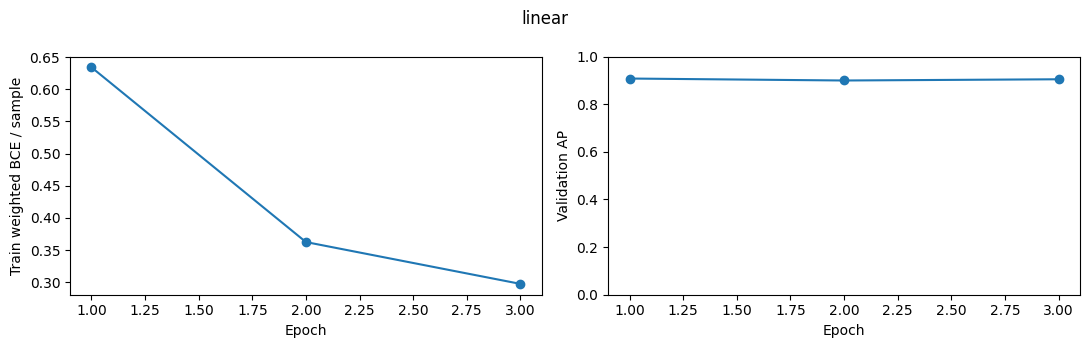

고정 encoder 확인 완료 / 학습 파라미터: 1537


In [ ]:
linear_run = fit_classifier(
    linear_model, linear_train_x, train_targets, linear_val_x, val_targets, method='linear'
)
display(pd.DataFrame([linear_run['selection']]))
plot_learning_curve(linear_run)
print('고정 encoder 확인 완료 / 학습 파라미터:', linear_run['trainable_parameters'])

# 비교에 필요한 것은 작은 학습 state와 기록입니다. 다음 모델을 위해 메모리를 비웁니다.
del linear_model, linear_encoder, linear_train_x, linear_val_x
gc.collect()
torch.cuda.empty_cache()

**생각해 보기:** encoder를 고정해도 사전학습 특징에 선형 분류기를 학습하면 구분할 수 있습니다. 이번에는 작은 추가 행렬로 특징 자체도 조금 조정해 봅니다.

## 7. 실험 B: 가벼운 Q·V LoRA + Linear head

원래 가중치 $W_0$를 고정하고 $W_0x+(\alpha/r)BAx$를 계산합니다. B를 0으로 시작하므로 초기 변화량은 0입니다.

### 보통 어디에 LoRA를 붙이나요?

| 대상 | 의미와 사용 방식 |
|---|---|
| **Q·V** | 대표적인 가벼운 시작 구성입니다. 공식 LoRA 구현도 Q·V를 기본 예제로 사용합니다. |
| Q·K·V | attention의 세 투영을 모두 조정합니다. 이 코드에서는 설정만 바꿔 실험할 수 있습니다. |
| Q·K·V·O, MLP 선형층 | 더 넓게 적용하는 구성도 있습니다. 이번 실습은 간단하게 Q/K/V 안에서만 선택하도록 구현했습니다. |

**“두 개”는 Transformer 블록 두 개가 아니라, 각 선택한 블록 안의 Q 투영과 V 투영 두 종류**를 뜻합니다. Q는 어떤 정보를 찾을지, V는 attention으로 전달할 내용과 관련된 표현입니다. K 투영의 원래 가중치는 고정합니다.

원 논문과 공식 구현에서 Q·V가 효과적인 구성이었지만, 이는 ST-MEM ECG에서 항상 최적이라는 뜻은 아닙니다. 비교는 validation으로 결정합니다.

### r은 무엇이고 어떻게 고르나요?

- `r`은 추가 행렬의 중간 차원(rank)입니다. 블록 수나 attention head 수가 아닙니다.
- 기본값은 **2**입니다. 여유가 있으면 **4 → 8**로 비교하고, validation이 개선되는지 봅니다. 큰 r이 항상 좋은 것은 아닙니다.
- Q와 V **각각**에 `A: (r,768)`, `B: (768,r)`를 둡니다. 둘은 독립적인 A/B를 학습합니다.
- `alpha = 2*r`로 두어 r을 바꿀 때 `alpha/r=2`를 유지합니다. alpha는 변화량의 배율을, r은 표현 용량을 조절합니다.

### 기본 설정은 얼마나 가벼운가요?

`4개 블록 × 2개 투영 × r=2 × (768+768) = 24,576`개 adapter 파라미터입니다. head 1,537개를 더하면 **26,113개**를 학습합니다.

하나의 A를 공유하는 통합 QKV LoRA도 있습니다. 그래서 독립 Q·V 두 개로 바꾼다는 이유만으로 같은 r에서 무조건 작아지는 것은 아닙니다. 이 설정은 통합 QKV rank 4의 50,689개보다 학습 파라미터가 적습니다. 기본 encoder 크기와 활성값 메모리는 여전히 남습니다.

출처: [LoRA 논문 §7.1–7.2](https://arxiv.org/html/2106.09685v2), [공식 LoRA 구현의 Additional Notes](https://github.com/microsoft/LoRA#additional-notes).


### ★ LoRA를 조절하려면 아래 셀만 먼저 수정하세요

- `LORA_TARGETS`: 블록 안에서 Q/K/V 중 어디에 붙일지 정합니다.
- `LORA_RANK`: 각 adapter의 중간 차원을 정합니다.
- `LORA_LAST_N_BLOCKS`: encoder의 뒤쪽 블록 몇 개를 조정할지 정합니다.

블록 인덱스는 0부터 시작합니다. 12개 블록이면 마지막 4개는 `[8,9,10,11]`, 마지막 2개는 `[10,11]`, 전부는 `[0,...,11]`입니다. 실제 선택 코드는 모델 생성 셀의 `range(depth-last_n_blocks, depth)`에 있습니다.
전체 encoder의 12개 블록은 모두 순전파합니다. 이 설정은 선택한 뒤쪽 블록의 adapter만 학습하도록 정하는 값입니다. N을 늘리면 학습 파라미터뿐 아니라 역전파에 필요한 계산·활성값 메모리도 늘어날 수 있습니다.

마지막 4개는 이 실습의 가벼운 시작 설정이며 사용자가 고르는 값입니다. ST-MEM 구조가 정해 주는 필수 개수나 LoRA 논문의 고정 규칙은 아닙니다. 먼저 2개와 4개를 validation으로 비교해도 좋습니다.


In [ ]:
# LoRA 설정 네 가지
LORA_TARGETS = ('q', 'v')       # Q·V만 조정. 세 개를 쓰려면 ('q','k','v').
LORA_RANK = 2                  # 가벼운 기본값 2.
LORA_LAST_N_BLOCKS = 4         #  마지막 몇 개 블록? 4→[8,9,10,11], 2→[10,11].
LORA_ALPHA = 2 * LORA_RANK     # r을 바꿔도 alpha/r=2 유지. alpha 자체도 실험할 수 있습니다.

LORA_LR = 1e-4                # 추가 A/B의 학습률. head의 HEAD_LR과 구분합니다.
# 더 가볍게: r=2 + 마지막 2개 + Q/V → adapter 12,288 + head 1,537 = 13,825개.
# 위 설정을 변경한 뒤에는 아래의 모델 생성·학습·평가 셀도 순서대로 다시 실행합니다.
print('LoRA 설정:', LORA_TARGETS, 'r=', LORA_RANK, 'last_n=', LORA_LAST_N_BLOCKS,
      'alpha/r=', LORA_ALPHA / LORA_RANK)

LoRA 설정: ('q', 'v') r= 2 last_n= 4 alpha/r= 2.0


In [ ]:
class LowRankUpdate(nn.Module):
    """선형층 하나에 더할 변화량: x → A → B. 원래 선형층은 별도로 고정합니다."""
    def __init__(self, in_features, out_features, rank, reference_weight):
        super().__init__()
        # 원래 가중치와 같은 GPU/device와 dtype으로 만들어 장치 혼용을 피합니다.
        self.lora_A = nn.Parameter(reference_weight.new_empty((rank, in_features)))
        self.lora_B = nn.Parameter(reference_weight.new_zeros((out_features, rank)))
        nn.init.kaiming_uniform_(self.lora_A, a=np.sqrt(5))

    def forward(self, x):
        # A: (r,input), B: (output,r). F.linear는 마지막 특징 축에 작용합니다.
        return torch.nn.functional.linear(
            torch.nn.functional.linear(x, self.lora_A), self.lora_B
        )


class SelectiveQKVLoRA(nn.Module):
    """ST-MEM의 결합 QKV 선형층에서 선택한 Q/K/V에만 독립적인 LoRA를 더합니다."""
    def __init__(self, base, rank, alpha, targets):
        super().__init__()
        if not isinstance(rank, int) or isinstance(rank, bool) or rank < 1:
            raise ValueError('LORA_RANK는 1 이상의 정수로 정하세요.')
        targets = tuple(targets)
        if (not targets or len(targets) != len(set(targets))
                or not set(targets).issubset({'q', 'k', 'v'})):
            raise ValueError("LORA_TARGETS는 ('q','v')처럼 q/k/v 중 중복 없이 선택하세요.")
        if not np.isfinite(alpha) or alpha <= 0:
            raise ValueError('LORA_ALPHA는 양수여야 합니다.')
        if base.out_features % 3 != 0:
            raise ValueError('이 구현은 동일한 크기의 Q/K/V 세 부분을 전제로 합니다.')
        self.base = base
        self.rank = rank
        self.scaling = alpha / rank
        for parameter in self.base.parameters():
            parameter.requires_grad = False
        # 공식 ST-MEM은 [Q, K, V]를 이어 출력한 뒤 chunk(3)으로 나눕니다.
        self.projection_width = base.out_features // 3
        # ModuleDict는 이름이 붙은 모듈 모음입니다. q/v의 A/B가 학습 파라미터로 등록됩니다.
        self.lora_adapters = nn.ModuleDict({
            name: LowRankUpdate(base.in_features, self.projection_width, rank, base.weight)
            for name in targets
        })

    def forward(self, x):
        # 기본 Q/K/V는 사전학습 가중치로 계산합니다.
        original_parts = self.base(x).chunk(3, dim=-1)
        parts = []
        for name, original in zip(('q', 'k', 'v'), original_parts):
            if name in self.lora_adapters:
                original = original + self.scaling * self.lora_adapters[name](x)
            # 기본 설정에서 K에는 변화량을 더하지 않습니다.
            # K 투영 가중치는 고정되지만, 앞 블록이 바뀌면 K에 들어오는 입력은 바뀔 수 있습니다.
            parts.append(original)
        return torch.cat(parts, dim=-1)  # 다시 [Q,K,V]로 연결해 원래 attention에 반환


class LoRABagClassifier(nn.Module):
    def __init__(self, encoder, *, rank, alpha, targets, last_n_blocks):
        super().__init__()
        self.encoder = encoder
        for parameter in self.encoder.parameters():
            parameter.requires_grad = False
        # 실험 A와 같은 크기의 head를 기본 초기화로 만듭니다.
        # 두 모형 모두 encoder를 읽은 직후 head를 만들도록 순서를 단순하게 맞춥니다.
        self.head = nn.Linear(1536, 1)
        depth = encoder.depth
        if (not isinstance(last_n_blocks, int) or isinstance(last_n_blocks, bool)
                or not 1 <= last_n_blocks <= depth):
            raise ValueError(f'LORA_LAST_N_BLOCKS는 1~{depth} 사이 정수로 정하세요.')

        # ★ 마지막 N개를 고르는 실제 코드입니다.
        # depth=12, N=4 → range(8,12) → [8,9,10,11]. 인덱스는 0부터 시작합니다.
        block_indices = list(range(depth - last_n_blocks, depth))
        for block_number in block_indices:
            attention = getattr(self.encoder, f'block{block_number}').attn.fn
            attention.to_qkv = SelectiveQKVLoRA(attention.to_qkv, rank, alpha, targets)
        self.lora_config = {'rank': rank, 'alpha': alpha, 'targets': list(targets),
                            'last_n_blocks': last_n_blocks, 'blocks': block_indices}

    def forward(self, x):
        batch, crops, channels, length = x.shape
        h = self.encoder(x.reshape(batch * crops, channels, length)).reshape(batch, crops, 768)
        features = torch.cat([h.mean(dim=1), h.amax(dim=1)], dim=1)
        return self.head(features).squeeze(1)

lora_encoder = make_encoder()
example_crop = torch.from_numpy(bags[:1, 0]).to(DEVICE)
with torch.inference_mode():
    before_lora = lora_encoder(example_crop).detach().cpu()
lora_model = LoRABagClassifier(
    lora_encoder, rank=LORA_RANK, alpha=LORA_ALPHA,
    targets=LORA_TARGETS, last_n_blocks=LORA_LAST_N_BLOCKS,
).to(DEVICE)
with torch.inference_mode():
    after_lora = lora_model.encoder(example_crop).detach().cpu()
assert torch.equal(before_lora, after_lora), 'B=0일 때 encoder 출력이 달라졌습니다.'

# 파라미터 수를 고정 숫자로 가정하지 않고, 바꾼 설정에서 실제 수를 셉니다.
adapter_rows = []
for block_index in lora_model.lora_config['blocks']:
    wrapper = getattr(lora_model.encoder, f'block{block_index}').attn.fn.to_qkv
    for target, adapter in wrapper.lora_adapters.items():
        adapter_rows.append({
            'block_index': block_index, 'projection': target.upper(), 'rank': wrapper.rank,
            'A_shape': tuple(adapter.lora_A.shape), 'B_shape': tuple(adapter.lora_B.shape),
            'parameters': sum(p.numel() for p in adapter.parameters()),
        })
adapter_table = pd.DataFrame(adapter_rows)
adapter_count = int(adapter_table['parameters'].sum())
head_count = sum(p.numel() for p in lora_model.head.parameters())
actual_count = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
assert actual_count == adapter_count + head_count
print('전체 블록 수:', lora_encoder.depth)
print('선택한 블록 인덱스:', lora_model.lora_config['blocks'])
print('선택한 투영:', LORA_TARGETS, '/ rank:', LORA_RANK, '/ alpha/r:', LORA_ALPHA / LORA_RANK)
print(f'학습 파라미터: adapter {adapter_count:,} + head {head_count:,} = {actual_count:,}')
display(adapter_table)
print('LoRA B=0에서 원래 encoder 출력과 일치: PASS')


공개 encoder를 읽었습니다. 모든 기본 가중치는 고정합니다.
전체 블록 수: 12
선택한 블록 인덱스: [8, 9, 10, 11]
선택한 투영: ('q', 'v') / rank: 2 / alpha/r: 2.0
학습 파라미터: adapter 24,576 + head 1,537 = 26,113


,block_index,projection,rank,A_shape,B_shape,parameters
0,8,Q,2,"(2, 768)","(768, 2)",3072
1,8,V,2,"(2, 768)","(768, 2)",3072
2,9,Q,2,"(2, 768)","(768, 2)",3072
3,9,V,2,"(2, 768)","(768, 2)",3072
4,10,Q,2,"(2, 768)","(768, 2)",3072
5,10,V,2,"(2, 768)","(768, 2)",3072
6,11,Q,2,"(2, 768)","(768, 2)",3072
7,11,V,2,"(2, 768)","(768, 2)",3072


LoRA B=0에서 원래 encoder 출력과 일치: PASS


### 7-1. LoRA 학습 실행

LoRA에서는 encoder 표현이 갱신되므로 실험 A의 고정 특징을 재사용하면 안 됩니다. 이번에는 **raw bag**을 학습 함수에 전달합니다. 함수 안에서 매번 encoder를 통과하고 A/B와 head에 gradient를 계산합니다.

`eval()`은 dropout 등의 동작을 바꾸는 함수이며 가중치 고정을 뜻하지 않습니다. 가중치 갱신 여부는 `requires_grad`와 optimizer에 넘기는 파라미터로 정합니다. 예측할 때는 `eval()`과 `inference_mode()`를 함께 사용합니다.
설정을 바꾸었다면 **설정 셀 → LoRA 모델 생성 셀 → LoRA 학습 셀 → Test 비교/저장 셀**을 다시 실행하세요. rank나 대상 블록을 바꾸고 이전 adapter 파일을 그대로 넣으면 구조가 달라질 수 있습니다. 새 설정에서 학습한 state와 함께 저장된 설정을 사용합니다.


lora epoch 1/3:   0%|          | 0/714 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

lora epoch 1 loss 0.633592779312481 val AP 0.9086998733738676


lora epoch 2/3:   0%|          | 0/714 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

lora epoch 2 loss 0.3567600064501375 val AP 0.903016253752319


lora epoch 3/3:   0%|          | 0/714 [00:00<?, ?it/s]

Validation:   0%|          | 0/90 [00:00<?, ?it/s]

lora epoch 3 loss 0.2845197421308158 val AP 0.9098791636854218


Best validation model:   0%|          | 0/90 [00:00<?, ?it/s]

,epoch,val_AP,threshold
0,3,0.909879,0.42


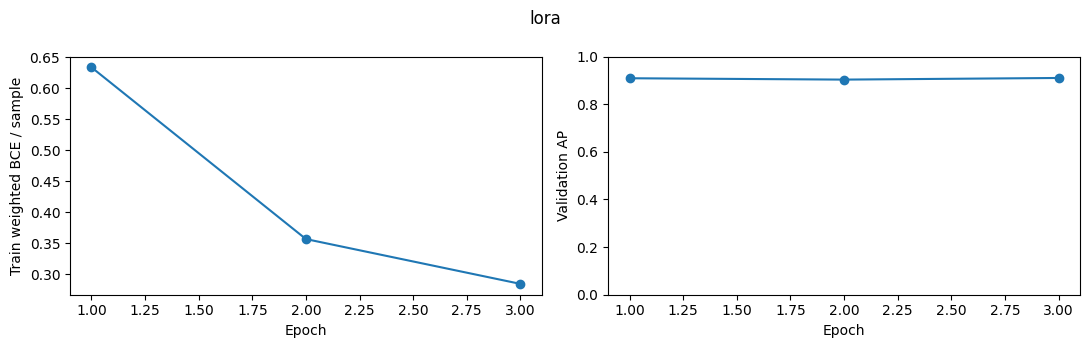

원래 encoder 가중치 고정 확인 완료 / 학습 파라미터: 26113


In [ ]:
lora_run = fit_classifier(
    lora_model, bags[split_masks['train']], train_targets,
    bags[split_masks['val']], val_targets, method='lora'
)
display(pd.DataFrame([lora_run['selection']]))
plot_learning_curve(lora_run)
print('원래 encoder 가중치 고정 확인 완료 / 학습 파라미터:', lora_run['trainable_parameters'])
del lora_model, lora_encoder, example_crop
gc.collect()
torch.cuda.empty_cache()

## 8. 마지막 Test 비교

이제 두 모델의 **epoch와 임계값을 모두 고정**했습니다. test는 여기에서 평가하며, 점수를 본 뒤 rank·학습률·임계값을 바꾸지 않습니다.

| 구분 | Linear head only | LoRA + head |
|---|---|---|
| Encoder 기본 가중치 | 고정 | 고정 |
| 학습 가능한 것 | head | 선택한 Q/V의 A/B와 head |
| 학습 파라미터 | 1,537 | 기본값 26,113 (설정에 따라 자동 계산) |
| 입력·pooling·head 초기값 | 동일 | 동일 |
| head 학습률·epoch·분할 | 동일 | 동일 |

AP/AUROC는 점수 순위, BAcc/F1/혼동행렬은 **검증에서 고른 임계값으로 판정한 결과**입니다. FP는 V가 없는데 있다고 예측한 구간, FN은 V가 있는데 놓친 구간입니다.
기록별 표에서 정답이 한 종류만 있는 기록은 이 예제의 AP/AUROC/BAcc를 `NaN`으로 표시합니다. 두 클래스를 함께 비교하는 평가 조건을 충족하지 않는다는 뜻이며 실행 오류가 아닙니다. 전체 test 표와 기록별 표를 구분해 읽으세요.


In [ ]:
# 평가용 모델을 새로 만든 뒤, 선택한 epoch의 작은 학습 state를 넣습니다.
# 공개 encoder 파일과 저장한 head/LoRA 파일을 함께 사용해야 합니다.
def rebuild_model(method):
    # 평가/재로딩할 때도 같은 공개 가중치와 같은 모델 구조를 먼저 만듭니다.
    encoder = make_encoder()
    if method == 'linear':
        return HeadOnlyBagClassifier(encoder).to(DEVICE)
    # 현재 설정 셀의 값이 아니라 실제 학습한 run의 설정으로 재구성합니다.
    config = runs[method]['lora_config']
    return LoRABagClassifier(
        encoder, rank=config['rank'], alpha=config['alpha'],
        targets=config['targets'], last_n_blocks=config['last_n_blocks'],
    ).to(DEVICE)


runs = {'linear': linear_run, 'lora': lora_run}
model_names = {'linear': 'Linear head only', 'lora': 'LoRA + head'}
comparison_rows = []
test_predictions = {}
record_rows = []

for method, run in runs.items():
    net = rebuild_model(method)
    load_trainable_state(net, run['state'])
    scores = predict_scores(net, bags[split_masks['test']], model_names[method] + ' test')
    threshold = run['selection']['threshold']
    # Test에서도 30초 구간 하나에 예측 하나입니다.
    table = meta.loc[split_masks['test']].reset_index(drop=True).copy()
    table['score'] = scores
    table['prediction'] = (scores >= threshold).astype(int)
    test_predictions[method] = table
    comparison_rows.append({
        'model': model_names[method], 'trainable_parameters': run['trainable_parameters'],
        **run['selection'], **classification_metrics(table.target, scores, threshold)
    })
    for record, group in table.groupby('record'):
        record_rows.append({'model': model_names[method], 'record': record,
                            **classification_metrics(group.target, group.score, threshold)})
    folder = OUT / method
    folder.mkdir(exist_ok=True)
    table.to_csv(folder / 'test_predictions.csv', index=False)
    del net
    gc.collect()
    torch.cuda.empty_cache()

comparison = pd.DataFrame(comparison_rows)
by_record = pd.DataFrame(record_rows)
comparison.to_csv(OUT / 'test_comparison.csv', index=False)
by_record.to_csv(OUT / 'test_metrics_by_record.csv', index=False)
display(comparison.round(4))
display(by_record.round(4))

공개 encoder를 읽었습니다. 모든 기본 가중치는 고정합니다.


Linear head only test:   0%|          | 0/90 [00:00<?, ?it/s]

공개 encoder를 읽었습니다. 모든 기본 가중치는 고정합니다.


LoRA + head test:   0%|          | 0/90 [00:00<?, ?it/s]

,model,trainable_parameters,epoch,val_AP,threshold,AP,AUROC,BAcc,F1,recall,specificity,TN,FP,FN,TP
0,Linear head only,1537,1,0.9075,0.49,0.9992,0.9986,0.6417,0.8464,1.0,0.2833,34,86,0,237
1,LoRA + head,26113,3,0.9099,0.42,0.9989,0.9981,0.8792,0.9423,1.0,0.7583,91,29,0,237


,model,record,AP,AUROC,BAcc,F1,recall,specificity,TN,FP,FN,TP
0,Linear head only,117,NaN,NaN,NaN,0.0000,0.0,0.2857,34,85,0,0
1,Linear head only,203,NaN,NaN,NaN,1.0000,1.0,NaN,0,0,0,119
2,Linear head only,208,0.9999,0.9831,0.5,0.9958,1.0,0.0000,0,1,0,118
3,LoRA + head,117,NaN,NaN,NaN,0.0000,0.0,0.7647,91,28,0,0
4,LoRA + head,203,NaN,NaN,NaN,1.0000,1.0,NaN,0,0,0,119
5,LoRA + head,208,0.9999,0.9831,0.5,0.9958,1.0,0.0000,0,1,0,118


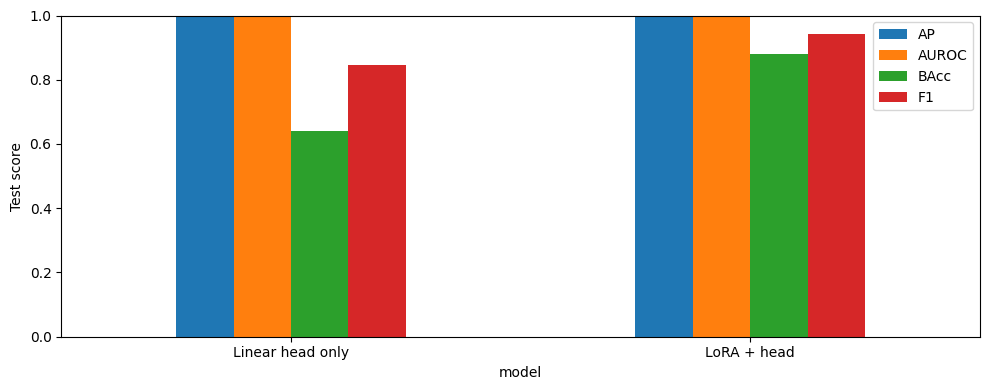

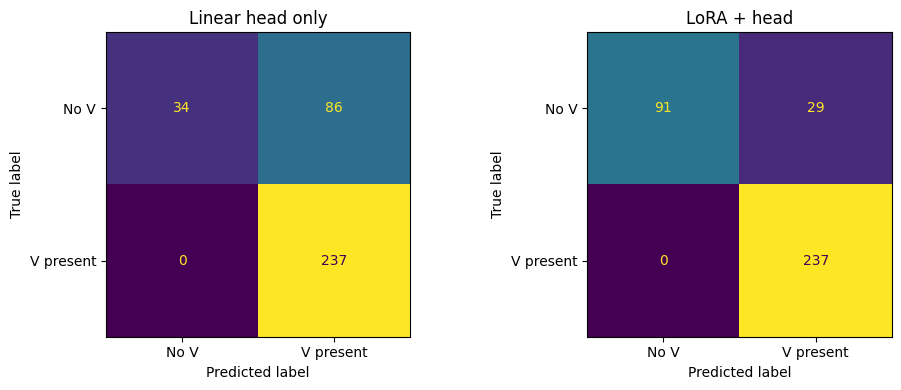

In [ ]:
# 점수 비교와 오류 유형을 함께 봅니다. 한 지표만으로 결론을 내리지 않습니다.
comparison.set_index('model')[['AP', 'AUROC', 'BAcc', 'F1']].plot.bar(
    figsize=(10, 4), ylim=(0, 1), rot=0
)
plt.ylabel('Test score')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, method in zip(axes, ['linear', 'lora']):
    table = test_predictions[method]
    ConfusionMatrixDisplay.from_predictions(
        table.target, table.prediction, labels=[0, 1],
        display_labels=['No V', 'V present'], colorbar=False, ax=axis,
    )
    axis.set_title(model_names[method])
plt.tight_layout()
plt.show()

## 9. 작은 학습 파라미터만 저장하고 다시 불러오기

공개 encoder 전체를 저장하지 않고 **linear head**, 또는 **LoRA A/B + head**만 저장합니다. 따라서 재사용할 때도 같은 공개 checkpoint가 필요합니다.

아래 셀은 저장한 파라미터를 다시 읽어, 같은 입력에 같은 logit이 나오는지 확인합니다.

In [ ]:
settings = {
    'repo': 'https://github.com/vuno/ST-MEM', 'commit': COMMIT,
    'checkpoint_sha256': weight_sha, 'lead_embedding_index': LEAD_INDEX,
    'lead_input': 'MLII approximated by standard II',
    'fs_hz': FS, 'window_s': WINDOW_S, 'hop_s': HOP_S,
    'crop_s': CROP_S, 'starts_s': STARTS_S,
    'filter': 'per-crop 5th highpass .67 then lowpass40, sosfiltfilt, offline',
    'normalization': 'per-crop zscore', 'pooling': 'mean + coordinatewise max',
    'epochs': EPOCHS, 'seed': SEED, 'head_lr': HEAD_LR,
    'batch_bags': BAG_BATCH, 'accum_steps': ACCUM_STEPS, 'weight_decay': 1e-3,
    'splits': SPLITS, 'amp': str(AMP_DTYPE) if AMP_ENABLED else 'float32',
    'initialization': 'ordinary nn.Linear; no historical-result replay',
    'selection': 'max validation AP epoch; max validation BAcc threshold',
    'quantization': 'none',
}

for method, run in runs.items():
    folder = OUT / method
    method_settings = {**settings, 'method': method,
                       'trainable_parameters': run['trainable_parameters']}
    if method == 'lora':
        method_settings['lora'] = run['lora_config']
    checkpoint_file = folder / 'trained_parameters.pt'
    torch.save({'trainable_state': run['state'], 'settings': method_settings,
                'selection': run['selection']}, checkpoint_file)
    (folder / 'settings.json').write_text(json.dumps(method_settings, ensure_ascii=False, indent=2), encoding='utf-8')
    pd.DataFrame(run['history']).to_csv(folder / 'learning_curve.csv', index=False)

    net = rebuild_model(method)
    load_trainable_state(net, run['state'])
    net.eval()
    sample = torch.from_numpy(bags[:2]).to(DEVICE)
    with torch.inference_mode():
        before_reload = net(sample).float().cpu()
    # 학습 가능한 부분만 일단 0으로 만든 뒤 저장 파일로 복원합니다.
    with torch.no_grad():
        for parameter in net.parameters():
            if parameter.requires_grad:
                parameter.zero_()
    saved = torch.load(checkpoint_file, map_location='cpu', weights_only=True)
    assert saved['settings']['checkpoint_sha256'] == weight_sha
    load_trainable_state(net, saved['trainable_state'])
    with torch.inference_mode():
        after_reload = net(sample).float().cpu()
    torch.testing.assert_close(before_reload, after_reload, rtol=0, atol=0)
    print(model_names[method], '저장/재로딩 예측 일치: PASS')
    del net, sample
    gc.collect()
    torch.cuda.empty_cache()

print('실행 결과 폴더:', OUT)

공개 encoder를 읽었습니다. 모든 기본 가중치는 고정합니다.
Linear head only 저장/재로딩 예측 일치: PASS
공개 encoder를 읽었습니다. 모든 기본 가중치는 고정합니다.
LoRA + head 저장/재로딩 예측 일치: PASS
실행 결과 폴더: /content/results/ecg_stmem_qv_light


## 10. 마무리

**결과 해석:** LoRA가 항상 더 좋아지는 것은 아닙니다. 이 실습은 소수 기록과 한 seed의 교육용 비교입니다. 겹치는 창들은 독립 표본이 아니며, MLII와 표준 II의 차이도 있습니다. V 포함 구간 탐지 점수를 임상 진단 성능으로 해석하지 않습니다.


참고: [ST-MEM](https://openreview.net/forum?id=WcOohbsF4H), [LoRA](https://arxiv.org/abs/2106.09685), [QLoRA](https://arxiv.org/abs/2305.14314).
